# Audit figure: stations reporting per day, 2017–2024

Evidence that a missing reading is an absent row: the number of stations reporting drops to zero during network
outages, although no field in the dataset is ever empty. Reads the audit outputs `<bucket>/audit/daily_stations/` and `<bucket>/audit/gaps/`.

Runs on Colab (secret `DSA5208_GS_BUCKET`, as in `task1_describe.ipynb`) or locally from `data/audit/`.

In [1]:
import os
from glob import glob

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

AUDIT, FIG_DIR = 'data/audit', 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

In [2]:
d = pd.concat(pd.read_csv(f) for f in glob(f'{AUDIT}/daily_stations/*.csv'))
# Stations reporting, averaged over all 288 intervals of the day: intervals with no report count as 0.
d['stations'] = d.mean_stations * d.buckets / 288
days = pd.date_range('2017-01-01', '2024-12-31')
# Days with no report at all have no row in the audit output, so they are added back as 0.
daily = d.groupby(pd.to_datetime(d.day)).stations.sum().reindex(days, fill_value=0)

# Network-wide outages longer than 5 days, from the audit's gap list.
gaps = pd.concat(pd.read_csv(f) for f in glob(f'{AUDIT}/gaps/*.csv'))
OUTAGES = gaps[gaps.gap_min > 5 * 1440]
print('days with no report at all:', (daily == 0).sum())
daily.describe().round(1)

days with no report at all: 64


count    2922.0
mean       57.7
std        13.4
min         0.0
25%        50.2
50%        61.4
75%        67.2
max        76.4
Name: stations, dtype: float64

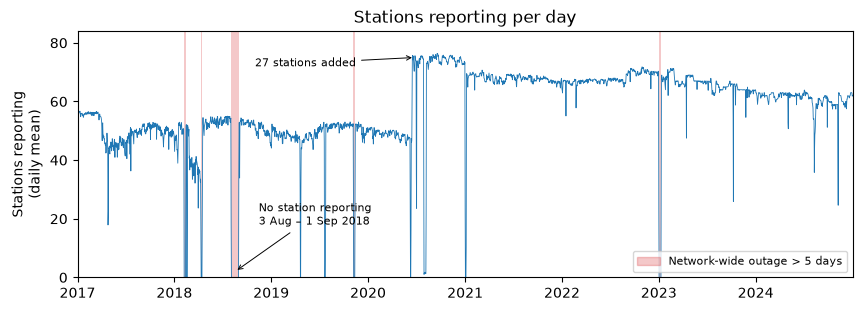

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(daily.index, daily.values, lw=0.6, color='tab:blue')
for start, end in zip(OUTAGES.last_before_gap, OUTAGES.first_after_gap):
    ax.axvspan(pd.Timestamp(start[:10]), pd.Timestamp(end[:10]), color='tab:red', alpha=0.25, lw=0)
ax.annotate('No station reporting\n3 Aug – 1 Sep 2018', xy=(pd.Timestamp('2018-08-18'), 2),
            xytext=(pd.Timestamp('2018-11-15'), 18), fontsize=8, arrowprops=dict(arrowstyle='->', lw=0.7))
ax.annotate('27 stations added', xy=(pd.Timestamp('2020-06-25'), 75),
            xytext=(pd.Timestamp('2018-11-01'), 72), fontsize=8, arrowprops=dict(arrowstyle='->', lw=0.7))
ax.set_ylabel('Stations reporting\n(daily mean)')
ax.set_ylim(0, daily.max() * 1.1)
ax.set_xlim(days[0], days[-1])
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend([plt.Rectangle((0, 0), 1, 1, color='tab:red', alpha=0.25)], ['Network-wide outage > 5 days'],
          loc='lower right', fontsize=8)
ax.set_title('Stations reporting per day')
fig.savefig(f'{FIG_DIR}/0_stations_reporting.png', dpi=300, bbox_inches='tight')
plt.show()

## Table 4: annual rainfall, stations below their mean, and ENSO

Reads `data/task1/station_year.csv` (written by `task1_describe.ipynb`) and the NOAA CPC Oceanic Niño Index.
The 7-year station filter and the anomaly are applied again here, so the result matches the report whichever
`MIN_YEARS` the table was saved with.

In [4]:
import numpy as np

MIN_YEARS = 7   # as in task1_describe.ipynb
sy = pd.read_csv('data/task1/station_year.csv')
sy = sy[sy.groupby('station_id').year.transform('size') >= MIN_YEARS].copy()
sy['anomaly_pct'] = 100 * (sy.rate / sy.groupby('station_id').rate.transform('mean') - 1)

# ONI is a 3-month running mean, labelled with its centre month (DJF -> Jan).
SEASONS = ['DJF', 'JFM', 'FMA', 'MAM', 'AMJ', 'MJJ', 'JJA', 'JAS', 'ASO', 'SON', 'OND', 'NDJ']
oni = pd.read_csv('https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt', sep=r'\s+')
oni = (oni.assign(month=oni.SEAS.map({s: i + 1 for i, s in enumerate(SEASONS)}))
          .rename(columns={'YR': 'year', 'ANOM': 'oni'})[['year', 'month', 'oni']])
oni = oni[oni.year.between(2017, 2024)]

def phase(x):
    return np.select([x >= 0.5, x <= -0.5], ['El Niño', 'La Niña'], 'Neutral')

table4 = (sy.groupby('year')
            .agg(stations=('station_id', 'size'),
                 rainfall_mm=('annual_mm', 'mean'),
                 below_mean_pct=('anomaly_pct', lambda a: 100 * (a < 0).mean()))
            .join(oni.groupby('year').oni.mean().rename('mean_oni')))
table4['phase'] = phase(table4.mean_oni)
print('r(annual rainfall, mean ONI) =', round(np.corrcoef(table4.rainfall_mm, table4.mean_oni)[0, 1], 2))
table4.round({'rainfall_mm': 0, 'below_mean_pct': 0, 'mean_oni': 2})

r(annual rainfall, mean ONI) = -0.49


,stations,rainfall_mm,below_mean_pct,mean_oni,phase
year,,,,,
2017,34,2456.0,74.0,-0.06,Neutral
2018,36,2761.0,25.0,0.14,Neutral
2019,36,1696.0,100.0,0.65,El Niño
2020,36,2680.0,50.0,-0.21,Neutral
2021,36,2850.0,14.0,-0.65,La Niña
2022,36,2889.0,6.0,-0.78,La Niña
2023,36,2784.0,17.0,0.81,El Niño
2024,34,2679.0,32.0,0.41,Neutral


In [5]:
# Months in each phase, for the timing notes in Table 4 (e.g. "El Niño from June").
oni.assign(phase=phase(oni.oni)).pivot(index='year', columns='month', values='phase')

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2017,Neutral,Neutral,Neutral,Neutral,Neutral,Neutral,Neutral,Neutral,Neutral,Neutral,La Niña,La Niña
2018,La Niña,La Niña,La Niña,Neutral,Neutral,Neutral,Neutral,Neutral,El Niño,El Niño,El Niño,El Niño
2019,El Niño,El Niño,El Niño,El Niño,El Niño,El Niño,Neutral,Neutral,Neutral,El Niño,El Niño,El Niño
2020,El Niño,El Niño,El Niño,Neutral,Neutral,Neutral,Neutral,Neutral,La Niña,La Niña,La Niña,La Niña
2021,La Niña,La Niña,La Niña,La Niña,Neutral,Neutral,Neutral,Neutral,La Niña,La Niña,La Niña,La Niña
2022,La Niña,La Niña,La Niña,La Niña,La Niña,La Niña,La Niña,La Niña,La Niña,La Niña,La Niña,La Niña
2023,La Niña,Neutral,Neutral,Neutral,Neutral,El Niño,El Niño,El Niño,El Niño,El Niño,El Niño,El Niño
2024,El Niño,El Niño,El Niño,El Niño,Neutral,Neutral,Neutral,Neutral,Neutral,Neutral,Neutral,Neutral


## Monthly rainfall anomaly vs ONI, by season (§2.4)

Pearson correlation between each month's island rainfall anomaly (`data/task1/month_year.csv`, written by
`task1_describe.ipynb`) and the ONI of the same month, separately for June–October and November–February. Months
without enough data (February–April and August 2018) are left out.

In [6]:
my = pd.read_csv('data/task1/month_year.csv')
monthly = my.merge(oni, on=['year', 'month']).dropna(subset=['anomaly_mm'])
monthly['phase'] = phase(monthly.oni)

SEASON_MONTHS = {'June–October': [6, 7, 8, 9, 10], 'November–February': [11, 12, 1, 2], 'All months': list(range(1, 13))}
pd.DataFrame([{'season': name, 'months': len(m := monthly[monthly.month.isin(ms)]),
               'r': round(np.corrcoef(m.anomaly_mm, m.oni)[0, 1], 2)}
              for name, ms in SEASON_MONTHS.items()])

,season,months,r
0,June–October,39,-0.37
1,November–February,31,0.03
2,All months,92,-0.21


In [7]:
# June–October months under La Niña (positive anomalies), and 2019's July–October deficit.
jjaso = monthly[monthly.month.isin(SEASON_MONTHS['June–October'])]
print(jjaso[jjaso.phase == 'La Niña'][['year', 'month', 'oni', 'anomaly_mm']].round(2).to_string(index=False))
print()
print(jjaso[jjaso.year == 2019][['year', 'month', 'oni', 'anomaly_mm']].round(2).to_string(index=False))

 year  month   oni  anomaly_mm
 2020      9 -0.77       92.33
 2020     10 -1.00      -39.75
 2021      9 -0.64       55.24
 2021     10 -0.77      -45.56
 2022      6 -0.73      -22.56
 2022      7 -0.70      -31.36
 2022      8 -0.78       51.68
 2022      9 -0.87       28.46
 2022     10 -0.89      211.69

 year  month  oni  anomaly_mm
 2019      6 0.59      -16.82
 2019      7 0.38      -82.54
 2019      8 0.20     -146.35
 2019      9 0.31     -112.75
 2019     10 0.51      -52.64
